# DSK807 Applied Machine Learning
## L04: Time-Series Feature Engineering + Linear Regression

This practical continues our work on **feature engineering** and connects it directly to **Linear Regression**.

We will use one running example throughout:

> **Can we predict tomorrow's minimum temperature using information available today?**

By the end of the notebook, you will:
- inspect a time series and its seasonal structure;
- create lag, rolling, difference, calendar, cyclic, and Fourier features;
- split time-series data chronologically;
- train and evaluate a Linear Regression model;
- compare a simple model with a richer feature-engineered model;
- finish with a very small house-price regression example.

### Forecasting setup

At day \(t\), we use information available **up to day \(t\)** to predict:

$$
y_{t+1} = \text{temperature tomorrow}
$$

This is therefore a **one-step-ahead forecast**.


In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## **1. Load the temperature dataset**

We use the classic **Daily Minimum Temperatures in Melbourne** dataset.

The notebook first tries to load a local file called `daily-minimum-temperatures.csv`.
If it is not available, it loads a public copy from GitHub.


In [2]:
#@title Load dataset

local_file = "daily-minimum-temperatures.csv"
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"

try:
    df = pd.read_csv(local_file)
    print("Loaded local file.")
except FileNotFoundError:
    df = pd.read_csv(url)
    print("Loaded public dataset from GitHub.")

df.head()


Loaded public dataset from GitHub.


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [3]:
df.columns = ["Date", "Temp"]
df["Date"] = pd.to_datetime(df["Date"])
df["Temp"] = pd.to_numeric(df["Temp"], errors="coerce")

df = (
    df.dropna()
      .sort_values("Date")
      .set_index("Date")
)

display(df.head())
print("Rows:", len(df))
print("Period:", df.index.min().date(), "to", df.index.max().date())

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


Rows: 3650
Period: 1981-01-01 to 1990-12-31


## **2. Explore the time series**

Before creating features, inspect the data.

Questions:
1. Can you see a repeating yearly pattern?
2. Does the series appear to have a strong long-term trend?
3. Does tomorrow's temperature seem likely to depend on recent days?


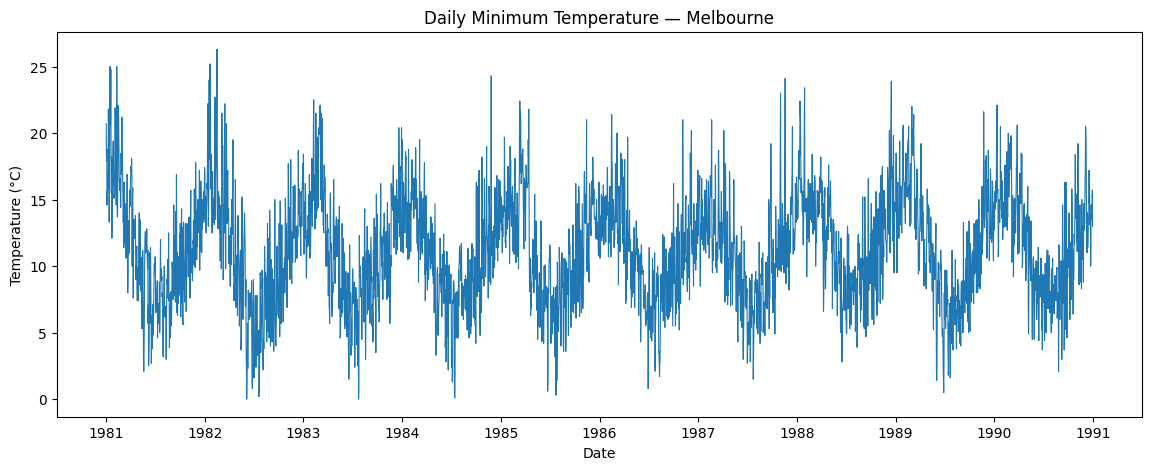

In [4]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Temp"], linewidth=0.8)
plt.title("Daily Minimum Temperature — Melbourne")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()


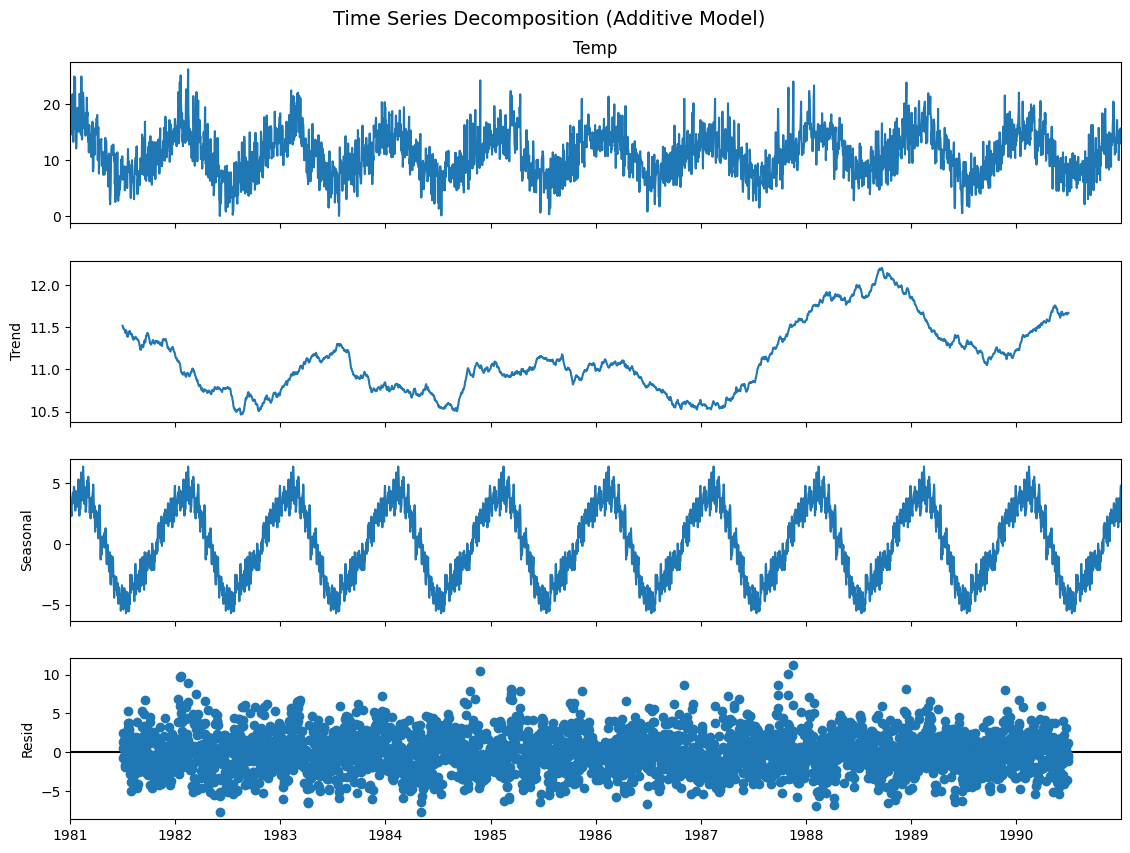

In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(df['Temp'], model='additive', period=365)

# --- Plot decomposition components ---
fig = decomposition.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Time Series Decomposition (Additive Model)", fontsize=14)
plt.show()

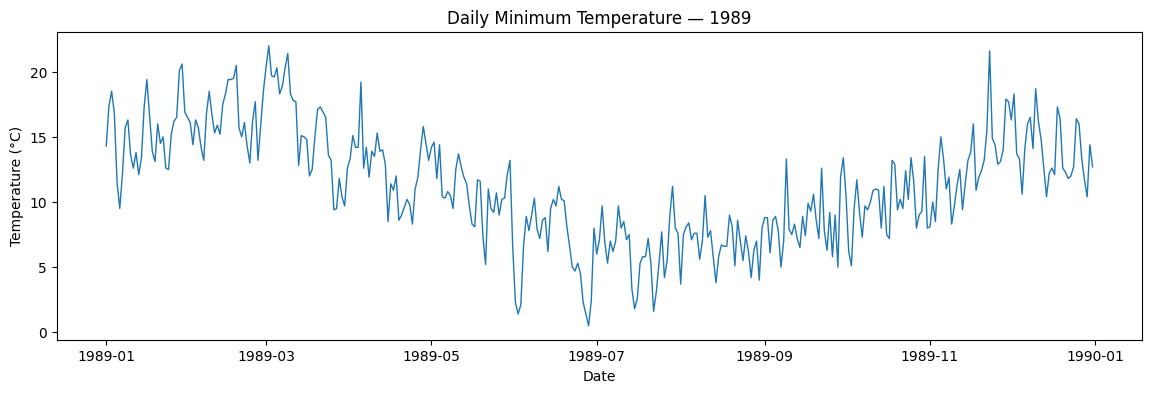

In [ ]:
# Zoom into one year
one_year = df.loc["1989"]

plt.figure(figsize=(14, 4))
plt.plot(one_year.index, one_year["Temp"], linewidth=1)
plt.title("Daily Minimum Temperature — 1989")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()


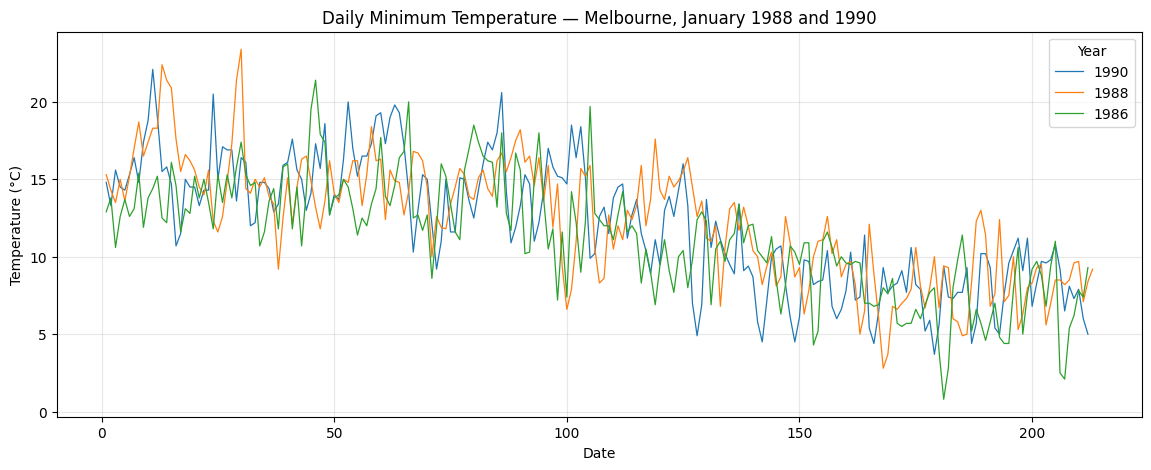

In [ ]:
# Check patterns over years
august_1990 = df.loc["1990-01-01":"1990-07-31"]
august_1988 = df.loc["1988-01-01":"1988-07-31"]
august_1986 = df.loc["1986-01-01":"1986-07-31"]
plt.figure(figsize=(14, 5))

plt.plot(
    august_1990.index.dayofyear,
    august_1990["Temp"],
    label="1990",
    linewidth=0.9
)

plt.plot(
    august_1988.index.dayofyear,
    august_1988["Temp"],
    label="1988",
    linewidth=0.9
)

plt.plot(
    august_1986.index.dayofyear,
    august_1986["Temp"],
    label="1986",
    linewidth=0.9
)


plt.title("Daily Minimum Temperature — Melbourne, January 1988 and 1990")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

# plt.xticks(range(1, 32))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()

## **3. Create the forecasting target**

A very important design choice:

- `Temp` = temperature **today**
- `target` = temperature **tomorrow**

We shift the target one step backwards so that each row contains today's information and tomorrow's value.


In [ ]:
data = df.copy()

data["target"] = data["Temp"].shift(-1)

display(data.head())


,Temp,target
Date,,
1981-01-01,20.7,17.9
1981-01-02,17.9,18.8
1981-01-03,18.8,14.6
1981-01-04,14.6,15.8
1981-01-05,15.8,15.8


# **Time-Series Feature Engineering**

The raw series contains only a date and temperature.  
We now transform it into a conventional machine-learning table \(X\) and \(y\).


## **4. Lag Features**

Lag features expose recent observations explicitly to the model.

For example:

- `Temp_lag1` = yesterday
- `Temp_lag2` = two days ago
- `Temp_lag7` = one week ago

Because `Temp` already represents today's known temperature, we also keep it as a feature.


In [ ]:
for lag in [1, 2, 3, 7, 14]:
    data[f"Temp_lag{lag}"] = data["Temp"].shift(lag)

display(
    data[["Temp", "Temp_lag1", "Temp_lag2", "Temp_lag3",
          "Temp_lag7", "Temp_lag14", "target"]].head(16)
)


,Temp,Temp_lag1,Temp_lag2,Temp_lag3,Temp_lag7,Temp_lag14,target
Date,,,,,,,
1981-01-01,20.7,NaN,NaN,NaN,NaN,NaN,17.9
1981-01-02,17.9,20.7,NaN,NaN,NaN,NaN,18.8
1981-01-03,18.8,17.9,20.7,NaN,NaN,NaN,14.6
1981-01-04,14.6,18.8,17.9,20.7,NaN,NaN,15.8
1981-01-05,15.8,14.6,18.8,17.9,NaN,NaN,15.8
1981-01-06,15.8,15.8,14.6,18.8,NaN,NaN,15.8
1981-01-07,15.8,15.8,15.8,14.6,NaN,NaN,17.4
1981-01-08,17.4,15.8,15.8,15.8,20.7,NaN,21.8
1981-01-09,21.8,17.4,15.8,15.8,17.9,NaN,20.0


## **5. Rolling Window Statistics**

Rolling statistics summarize the **recent history** of the series.

Examples:
- rolling mean → local level / short-term trend
- rolling standard deviation → recent variability
- rolling minimum / maximum → recent range

Since today's temperature is known when predicting tomorrow, the window may include day \(t\).


In [ ]:
data["rolling_mean_7"] = data["Temp"].rolling(7).mean()
data["rolling_std_7"]  = data["Temp"].rolling(7).std()
data["rolling_min_7"]  = data["Temp"].rolling(7).min()
data["rolling_max_7"]  = data["Temp"].rolling(7).max()

display(
    data[["Temp", "rolling_mean_7", "rolling_std_7",
          "rolling_min_7", "rolling_max_7", "target"]].head(12)
)


,Temp,rolling_mean_7,rolling_std_7,rolling_min_7,rolling_max_7,target
Date,,,,,,
1981-01-01,20.7,NaN,NaN,NaN,NaN,17.9
1981-01-02,17.9,NaN,NaN,NaN,NaN,18.8
1981-01-03,18.8,NaN,NaN,NaN,NaN,14.6
1981-01-04,14.6,NaN,NaN,NaN,NaN,15.8
1981-01-05,15.8,NaN,NaN,NaN,NaN,15.8
1981-01-06,15.8,NaN,NaN,NaN,NaN,15.8
1981-01-07,15.8,17.057143,2.152407,14.6,20.7,17.4
1981-01-08,17.4,16.585714,1.476966,14.6,18.8,21.8
1981-01-09,21.8,17.142857,2.462287,14.6,21.8,20.0


## 6. Difference Features

A raw temperature value tells us the current level.

A **difference** tells us how the temperature is changing:

$$
\Delta_1 = T_t - T_{t-1}
$$

This can help the model distinguish, for example, a rising temperature pattern from a falling one.


In [ ]:
data["diff_1"] = data["Temp"] - data["Temp"].shift(1)
data["diff_7"] = data["Temp"] - data["Temp"].shift(7)

display(data[["Temp", "diff_1", "diff_7", "target"]].head(12))


,Temp,diff_1,diff_7,target
Date,,,,
1981-01-01,20.7,NaN,NaN,17.9
1981-01-02,17.9,-2.8,NaN,18.8
1981-01-03,18.8,0.9,NaN,14.6
1981-01-04,14.6,-4.2,NaN,15.8
1981-01-05,15.8,1.2,NaN,15.8
1981-01-06,15.8,0.0,NaN,15.8
1981-01-07,15.8,0.0,NaN,17.4
1981-01-08,17.4,1.6,-3.3,21.8
1981-01-09,21.8,4.4,3.9,20.0


## **7. Date-Time Features**

The timestamp itself contains useful information.

We can extract:
- month;
- day of year;
- day of week;
- weekend indicator;
- year.

These features allow a standard ML model to use temporal structure explicitly.


In [ ]:
data["month"] = data.index.month
data["dayofyear"] = data.index.dayofyear
data["dayofweek"] = data.index.dayofweek       # Monday=0 ... Sunday=6
data["is_weekend"] = (data["dayofweek"] >= 5).astype(int)
data["year"] = data.index.year

display(
    data[["Temp", "month", "dayofyear", "dayofweek",
          "is_weekend", "year", "target"]].head()
)


,Temp,month,dayofyear,dayofweek,is_weekend,year,target
Date,,,,,,,
1981-01-01,20.7,1,1,3,0,1981,17.9
1981-01-02,17.9,1,2,4,0,1981,18.8
1981-01-03,18.8,1,3,5,1,1981,14.6
1981-01-04,14.6,1,4,6,1,1981,15.8
1981-01-05,15.8,1,5,0,0,1981,15.8


## **8. Cyclic Encoding**

Calendar variables are **cyclic**.

For example, December and January are numerically `12` and `1`, but they are adjacent in time.

We encode a periodic variable \(x\) using:

$$
x_{\sin}=\sin\left(2\pi\frac{x}{P}\right), \qquad
x_{\cos}=\cos\left(2\pi\frac{x}{P}\right)
$$

where \(P\) is the period.


In [ ]:
# Month: period = 12
data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

# Day of week: use 1...7 to match the lecture notation
dow_1_to_7 = data["dayofweek"] + 1
data["dow_sin"] = np.sin(2 * np.pi * dow_1_to_7 / 7)
data["dow_cos"] = np.cos(2 * np.pi * dow_1_to_7 / 7)

display(
    data[["month", "month_sin", "month_cos",
          "dayofweek", "dow_sin", "dow_cos"]].head(10)
)


,month,month_sin,month_cos,dayofweek,dow_sin,dow_cos
Date,,,,,,
1981-01-01,1,0.5,0.866025,3,-4.338837e-01,-0.900969
1981-01-02,1,0.5,0.866025,4,-9.749279e-01,-0.222521
1981-01-03,1,0.5,0.866025,5,-7.818315e-01,0.623490
1981-01-04,1,0.5,0.866025,6,-2.449294e-16,1.000000
1981-01-05,1,0.5,0.866025,0,7.818315e-01,0.623490
1981-01-06,1,0.5,0.866025,1,9.749279e-01,-0.222521
1981-01-07,1,0.5,0.866025,2,4.338837e-01,-0.900969
1981-01-08,1,0.5,0.866025,3,-4.338837e-01,-0.900969
1981-01-09,1,0.5,0.866025,4,-9.749279e-01,-0.222521


## **Feature Correlation**

Now that we have created several features, we can examine how strongly
each one is associated with the **target: tomorrow's temperature**.

The correlation coefficient ranges from **-1 to +1**:

- **+1**: strong positive linear relationship
- **0**: little or no linear relationship
- **-1**: strong negative linear relationship

This gives us an initial indication of which engineered features may be
useful for Linear Regression.

> **Important:** Correlation does not tell us whether a feature will improve
> the model. Features may also contain overlapping information and interact
> with other features.

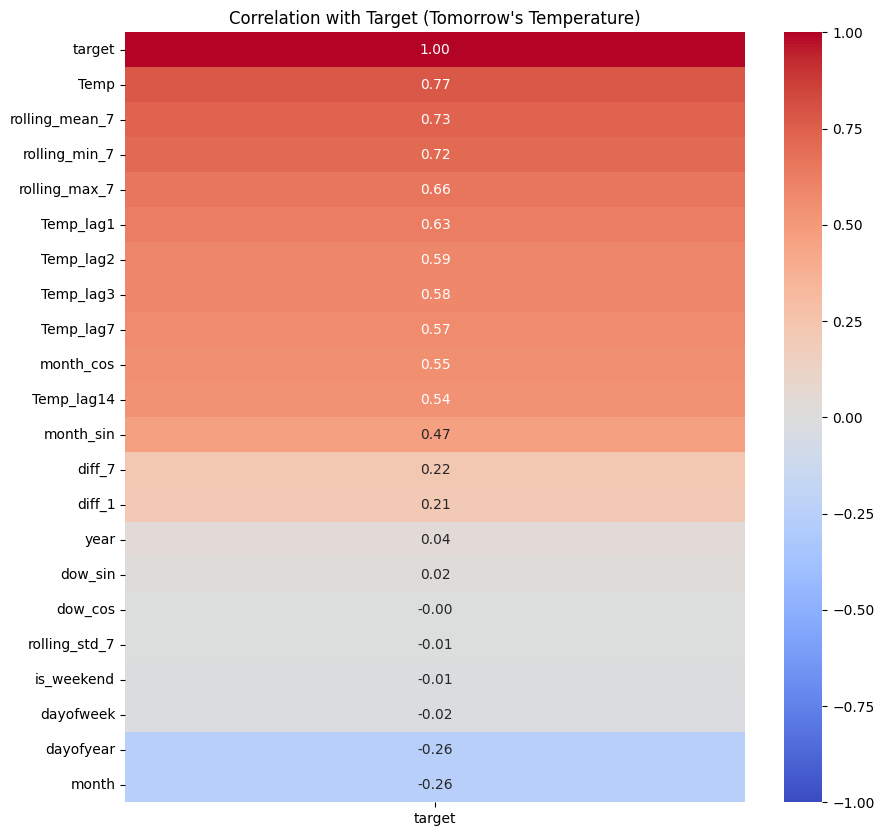

In [ ]:
import seaborn as sns

# Correlation of all numeric variables with tomorrow's temperature
corr_with_target = (
    data.corr(numeric_only=True)["target"]
        .sort_values(ascending=False)
        .to_frame()
)

plt.figure(figsize=(10, 10))

sns.heatmap(
    corr_with_target,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation with Target (Tomorrow's Temperature)")
plt.show()

## 10. Assemble the Machine-Learning Dataset

We now have:

- **recent-history features**: current temperature, lags, rolling statistics, differences;
- **calendar features**: month, day of year, weekend;
- **cyclic/Fourier features**: smooth representations of periodic structure;
- **target**: tomorrow's temperature.

Rows containing missing values are removed. These missing values are expected because lag and rolling features need previous observations.


In [ ]:
feature_cols = [
    # Current / lagged temperature
    "Temp",
    "Temp_lag1", "Temp_lag2", "Temp_lag3", "Temp_lag7", "Temp_lag14",

    # Rolling statistics
    "rolling_mean_7", "rolling_std_7",
    "rolling_min_7", "rolling_max_7",

    # Difference features
    "diff_1", "diff_7",

    # Calendar
    "month", "dayofyear", "dayofweek", "is_weekend",

    # Cyclic encoding
    "month_sin", "month_cos", "dow_sin", "dow_cos",
]

model_df = data[feature_cols + ["target"]].dropna().copy()

display(model_df.head())
print("Rows available for modelling:", len(model_df))


,Temp,Temp_lag1,Temp_lag2,Temp_lag3,Temp_lag7,Temp_lag14,rolling_mean_7,rolling_std_7,rolling_min_7,rolling_max_7,...,diff_7,month,dayofyear,dayofweek,is_weekend,month_sin,month_cos,dow_sin,dow_cos,target
Date,,,,,,,,,,,,,,,,,,,,,
1981-01-15,25.0,21.5,16.7,13.3,17.4,20.7,19.214286,4.008087,13.3,25.0,...,7.6,1,15,3,0,0.5,0.866025,-4.338837e-01,-0.900969,20.7
1981-01-16,20.7,25.0,21.5,16.7,21.8,17.9,19.057143,3.910182,13.3,25.0,...,-1.1,1,16,4,0,0.5,0.866025,-9.749279e-01,-0.222521,20.6
1981-01-17,20.6,20.7,25.0,21.5,20.0,18.8,19.142857,3.940752,13.3,25.0,...,0.6,1,17,5,1,0.5,0.866025,-7.818315e-01,0.623490,24.8
1981-01-18,24.8,20.6,20.7,25.0,16.2,14.6,20.371429,4.202267,13.3,25.0,...,8.6,1,18,6,1,0.5,0.866025,-2.449294e-16,1.000000,17.7
1981-01-19,17.7,24.8,20.6,20.7,13.3,15.8,21.000000,3.170699,16.7,25.0,...,4.4,1,19,0,0,0.5,0.866025,7.818315e-01,0.623490,15.5


Rows available for modelling: 3635


# Linear Regression

We now use the engineered time-series table with a standard supervised-learning model.

Linear Regression learns coefficients:

$$
\hat y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p
$$

The model itself is simple. The feature engineering determines what information it can use.


## 11. Chronological Train/Test Split

For time-series data we **do not shuffle**.

We train on the earlier observations and evaluate on later observations:

> past → future

Here we use the first 80% for training and the final 20% for testing.


In [ ]:
split_idx = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_idx]
test_df  = model_df.iloc[split_idx:]

print("Training:", train_df.index.min().date(), "to", train_df.index.max().date())
print("Test:    ", test_df.index.min().date(),  "to", test_df.index.max().date())
print("Train rows:", len(train_df))
print("Test rows: ", len(test_df))


Training: 1981-01-15 to 1989-01-02
Test:     1989-01-03 to 1990-12-30
Train rows: 2908
Test rows:  727


In [ ]:
X_train = train_df[feature_cols]
y_train = train_df["target"]

X_test = test_df[feature_cols]
y_test = test_df["target"]


## 12. Model A — Simple Linear Regression

First use only **today's temperature**:

$$
\widehat{T}_{t+1} = \beta_0 + \beta_1 T_t
$$

This gives us a simple regression model that is easy to interpret.


In [ ]:
simple_features = ["Temp"]

simple_model = LinearRegression()
simple_model.fit(train_df[simple_features], y_train)

simple_pred = simple_model.predict(test_df[simple_features])

print("Intercept:", round(simple_model.intercept_, 3))
print("Coefficient for today's temperature:", round(simple_model.coef_[0], 3))


Intercept: 2.651
Coefficient for today's temperature: 0.76


In [ ]:
simple_mae = mean_absolute_error(y_test, simple_pred)
simple_rmse = np.sqrt(mean_squared_error(y_test, simple_pred))
simple_r2 = r2_score(y_test, simple_pred)

print(f"Simple LR MAE:  {simple_mae:.2f} °C")
print(f"Simple LR RMSE: {simple_rmse:.2f} °C")
print(f"Simple LR R²:   {simple_r2:.3f}")


Simple LR MAE:  1.89 °C
Simple LR RMSE: 2.38 °C
Simple LR R²:   0.664


## 13. Model B — Linear Regression with Engineered Features

Now fit the **same algorithm** using the richer feature representation.

This lets us test one of the main messages of the lecture:

> A simple model can become much more useful when the data are represented well.


In [ ]:
full_model = LinearRegression()
full_model.fit(X_train, y_train)

full_pred = full_model.predict(X_test)

full_mae = mean_absolute_error(y_test, full_pred)
full_rmse = np.sqrt(mean_squared_error(y_test, full_pred))
full_r2 = r2_score(y_test, full_pred)

print(f"Engineered LR MAE:  {full_mae:.2f} °C")
print(f"Engineered LR RMSE: {full_rmse:.2f} °C")
print(f"Engineered LR R²:   {full_r2:.3f}")


Engineered LR MAE:  1.72 °C
Engineered LR RMSE: 2.17 °C
Engineered LR R²:   0.719


## 14. Compare the Models


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression: Temp only",
        "Linear Regression: engineered features"
    ],
    "MAE": [
        simple_mae,
        full_mae
    ],
    "RMSE": [
        simple_rmse,
        full_rmse
    ]
})

display(results.round(3))


,Model,MAE,RMSE
0,Linear Regression: Temp only,1.894,2.376
1,Linear Regression: engineered features,1.723,2.173


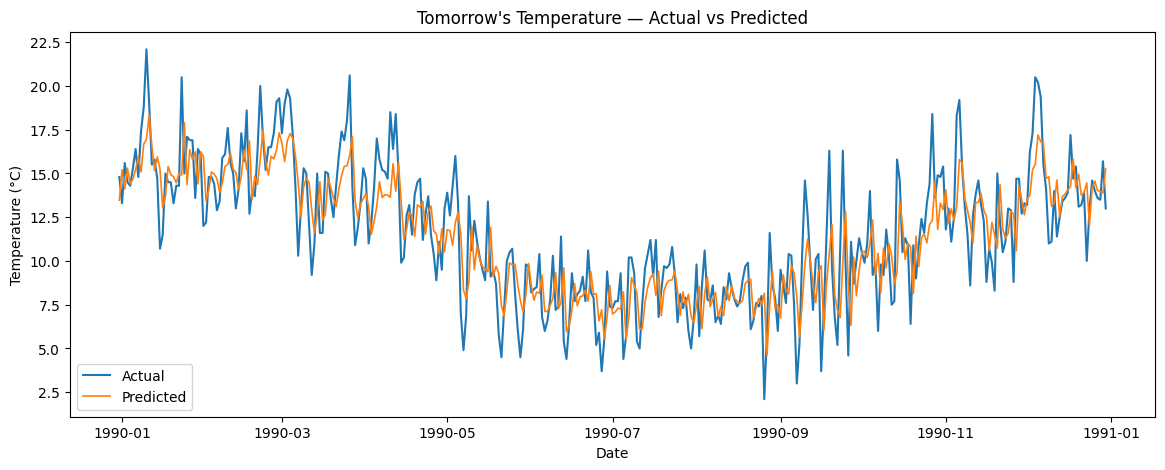

In [ ]:
# Plot predictions for the final 365 test observations
n = min(365, len(test_df))

plt.figure(figsize=(14, 5))
plt.plot(test_df.index[-n:], y_test.iloc[-n:], label="Actual", linewidth=1.5)
plt.plot(test_df.index[-n:], full_pred[-n:], label="Predicted", linewidth=1.2)
plt.title("Tomorrow's Temperature — Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()


## 15. Inspect the Learned Coefficients

Linear Regression gives one coefficient to each input feature.

Be careful with interpretation:
- coefficients depend on feature scale;
- correlated features can make individual coefficients unstable;
- a coefficient is not automatically a causal effect.

Still, inspecting the coefficients is useful for understanding what the fitted model is using.


In [ ]:
coef_table = (
    pd.DataFrame({
        "Feature": feature_cols,
        "Coefficient": full_model.coef_
    })
    .assign(AbsCoefficient=lambda x: x["Coefficient"].abs())
    .sort_values("AbsCoefficient", ascending=False)
)

display(coef_table[["Feature", "Coefficient"]].head(15))


,Feature,Coefficient
17,month_cos,1.293546
16,month_sin,0.854998
15,is_weekend,-0.377318
6,rolling_mean_7,0.273840
0,Temp,0.237862
10,diff_1,0.180961
18,dow_sin,0.158546
9,rolling_max_7,-0.148749
19,dow_cos,0.146897
4,Temp_lag7,0.131084


---

## **Example 2: Predicting Vehicle Fuel Efficiency**

We will now apply Linear Regression to a real-world regression problem.

The **Auto MPG dataset** contains information about cars and their technical
characteristics.

Our goal is to predict:

**Fuel efficiency (`mpg`) — measured in miles per gallon**

using characteristics such as:

- number of cylinders
- engine displacement
- horsepower
- vehicle weight
- acceleration
- model year

This is a standard regression problem because the target (`mpg`) is a
continuous numerical value.

In [ ]:

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

cars = pd.read_csv(url)

cars.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
print(cars.shape)
print(cars.info())

cars.describe()

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB
None


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [ ]:
features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

target = "mpg"

data = cars[features + [target]].dropna()

data.head()

,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
0,8,307.0,130.0,3504,12.0,70,18.0
1,8,350.0,165.0,3693,11.5,70,15.0
2,8,318.0,150.0,3436,11.0,70,18.0
3,8,304.0,150.0,3433,12.0,70,16.0
4,8,302.0,140.0,3449,10.5,70,17.0


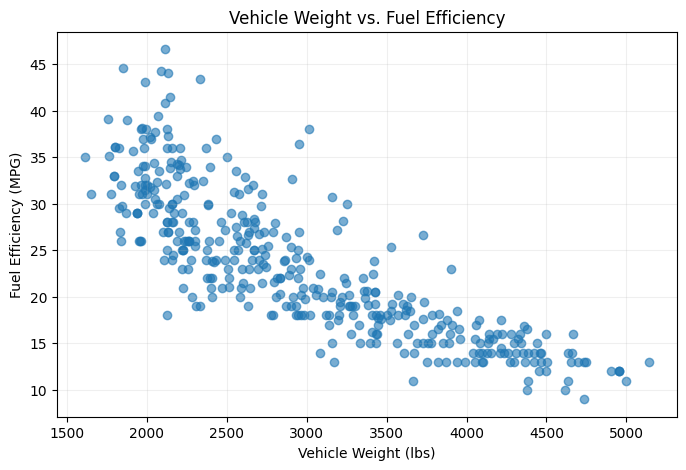

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    data["weight"],
    data["mpg"],
    alpha=0.6
)

plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Fuel Efficiency (MPG)")
plt.title("Vehicle Weight vs. Fuel Efficiency")
plt.grid(alpha=0.2)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f} MPG")
print(f"MSE:  {mse:.2f} MPG²")
print(f"RMSE: {rmse:.2f} MPG")
print(f"R²:   {r2:.2f}")

MAE:  2.50 MPG
MSE:  10.50 MPG²
RMSE: 3.24 MPG
R²:   0.79


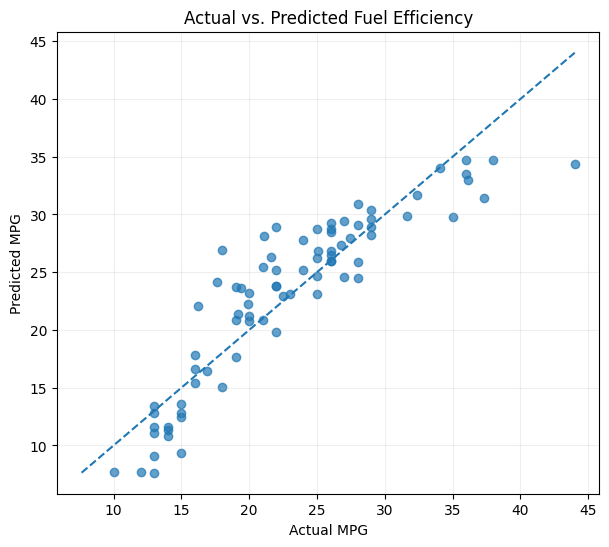

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs. Predicted Fuel Efficiency")
plt.grid(alpha=0.2)

plt.show()

In [ ]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    "Coefficient",
    key=abs,
    ascending=False
)

,Feature,Coefficient
5,model_year,0.760636
0,cylinders,-0.116173
4,acceleration,0.061736
3,weight,-0.006561
2,horsepower,-0.002276
1,displacement,0.001013
